# 02 · Decisión: ablación, beta OOF y ensamble

Parte 2 de 3. Mismo código que las secciones 6–8 del original.

**Requisito:** haber corrido el `01` (usa su `artifacts/`). No re-entrena la semilla 42.

In [1]:
# FIX ruta: los cuadernos viven en notebooks/ds02_ensemble pero los datos estan en la raiz.
# Se vuelve a la raiz para que archive/... y models/... resuelvan igual que en el original.
import pathlib as _pl
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
import os as _os
_os.chdir(_ROOT)
print("cwd:", _os.getcwd())
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd

import ds02_rul
from ds02_rul import calculate_nasa_score, evaluate_predictions, macro_rmse
from ds02_rul.conformal import apply_conformal, empirical_coverage, fit_conformal
from ds02_rul.data import load_ds02
from ds02_rul.features import build_windows, fit_preprocessing
from ds02_rul.model import build_champion_bilstm
from ds02_rul.persistence import build_manifest, load_ensemble, save_ensemble
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import (
    fit_meta_learners, in_sample_beta_diagnostic, meta_predict, select_beta_grouped,
)
from ds02_rul.pipeline import (
    ablation_table, make_lgbm, oof_base_predictions, run_seed, seed_summary,
)

import keras
import lightgbm as lgb
import sklearn

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2

print('python  :', sys.version.split()[0])
print('keras   :', keras.__version__)
print('lightgbm:', lgb.__version__)
print('sklearn :', sklearn.__version__)
print('ds02_rul:', ds02_rul.__version__, '->', os.path.dirname(ds02_rul.__file__))


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


python  : 3.12.10
keras   : 3.15.1
lightgbm: 4.7.0
sklearn : 1.9.1
ds02_rul: 4.1.0 -> C:\Users\mikel\Desktop\Pruebas\nasa\src\ds02_rul


In [2]:
# --- utilidades de presentación: importaciones ---
# `plt` se importa aquí, no en la celda de persistencia: las funciones
# de abajo lo usan y esa celda se ejecuta después de todos los gráficos.
import matplotlib.pyplot as plt

# --- paleta y etiquetas -----------------------------------------------------
# Un color por modelo, el mismo en todos los gráficos. Así el lector reconoce
# la serie sin volver a leer la leyenda.
PALETA = {
    'LightGBM solo': '#8C8C8C',
    'BiLSTM solo': '#4C72B0',
    'Híbrido + EMA5': '#1FA098',
}
COLORES_ABLACION = {'LGBM': '#8C8C8C', 'BiLSTM': '#4C72B0', 'BiLSTM+EMA': '#1FA098'}
NOMBRE_CORTO = {'LightGBM solo': 'LightGBM', 'BiLSTM solo': 'BiLSTM'}


def nombre_corto(modelo):
    """Etiqueta corta para los ejes; no toca el nombre que usan las tablas."""
    return NOMBRE_CORTO.get(modelo, modelo)


# --- tablas -----------------------------------------------------------------
def tabla_modelos(summary, metricas=('RMSE', 'MAE', 'R2', 'NASA_Score')):
    """Una fila por modelo con 'media ± desviación' en cada métrica.

    Ordena por RMSE medio y devuelve strings: es una tabla para leer, no para
    volver a calcular. Los decimales se eligen por métrica para que el ruido de
    las últimas cifras no se confunda con una diferencia.
    """
    orden = summary.sort_values('RMSE_mean')
    filas = []
    for _, fila in orden.iterrows():
        registro = {'Modelo': fila['Modelo']}
        for metrica in metricas:
            decimales = {'R2': 4, 'NASA_Score': 1}.get(metrica, 3)
            registro[metrica] = (f"{fila[f'{metrica}_mean']:.{decimales}f}"
                                 f" ± {fila[f'{metrica}_std']:.{decimales}f}")
        filas.append(registro)
    return pd.DataFrame(filas)


def comparar_con_base(summary, base, metricas=('RMSE', 'MAE')):
    """Cuánto mejora (o empeora) cada modelo frente a la base indicada.

    El delta es la diferencia directa de medias: negativo en RMSE/MAE significa
    que se equivoca menos. La columna 'mejora %' ya viene en positivo cuando
    mejora, para poder decirla en voz alta sin cambiar de signo.
    """
    fila_base = summary.loc[summary['Modelo'] == base].iloc[0]
    filas = []
    for _, fila in summary.sort_values('RMSE_mean').iterrows():
        registro = {'Modelo': fila['Modelo'], 'frente a': base}
        for metrica in metricas:
            delta = fila[f'{metrica}_mean'] - fila_base[f'{metrica}_mean']
            registro[f'delta {metrica}'] = round(float(delta), 3)
            registro[f'mejora {metrica} %'] = round(-100 * float(delta) / float(fila_base[f'{metrica}_mean']), 1)
        filas.append(registro)
    return pd.DataFrame(filas)


def tabla_por_motor(y_real, y_pred, unidades):
    """RMSE, MAE y sesgo de cada motor de test, por separado.

    Un promedio bueno puede esconder un motor malo: si un motor concentra el
    error, el número global no describe al modelo.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    unidades = np.asarray(unidades)
    filas = []
    for unidad in sorted(np.unique(unidades).tolist()):
        mask = unidades == unidad
        error = y_pred[mask] - y_real[mask]
        filas.append({
            'Motor': int(unidad),
            'Ventanas': int(mask.sum()),
            'RMSE': round(float(np.sqrt(np.mean(error ** 2))), 3),
            'MAE': round(float(np.mean(np.abs(error))), 3),
            'Sesgo': round(float(error.mean()), 3),
        })
    return pd.DataFrame(filas)


# --- gráficos ---------------------------------------------------------------
def barras_metricas(summary, metricas=('RMSE', 'MAE', 'R2', 'NASA_Score'), figsize=(11, 7)):
    """Barras horizontales de la media, con la desviación entre semillas como error.

    La rayita es la desviación: si dos barras se diferencian menos que eso, es
    un empate y no hay que elegir por el tercer decimal.
    """
    orden = summary.sort_values('RMSE_mean')
    etiquetas = [nombre_corto(m) for m in orden['Modelo']]
    colores = [PALETA.get(m, '#999999') for m in orden['Modelo']]

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    for ax, metrica in zip(axes.ravel(), metricas):
        ax.barh(etiquetas, orden[f'{metrica}_mean'].values,
                xerr=orden[f'{metrica}_std'].values, color=colores, capsize=5)
        ax.set_title(metrica)
        ax.set_xlabel('media ± desviación entre semillas')
        ax.grid(True, axis='x', ls='--', alpha=0.5)
        ax.invert_yaxis()
    fig.suptitle('Comparación de modelos sobre los motores 11/14/15', y=1.01)
    plt.tight_layout()
    plt.show()


def dispersion_por_semilla(seed_rows, metrica='RMSE', figsize=(9, 4)):
    """Un punto por semilla y una línea con la media.

    Si los puntos se abren mucho, el promedio no alcanza: hay que decir cuánto
    varía el modelo antes de declararlo ganador.
    """
    df = pd.DataFrame(seed_rows)
    modelos = [m for m in PALETA if m in set(df['Modelo'])]
    fig, ax = plt.subplots(figsize=figsize)
    for i, modelo in enumerate(modelos):
        valores = df.loc[df['Modelo'] == modelo, metrica].values
        if len(valores) == 0:
            continue
        x = np.full(len(valores), i) + np.linspace(-0.06, 0.06, len(valores))
        ax.scatter(x, valores, s=80, color=PALETA[modelo], zorder=3)
        ax.hlines(valores.mean(), i - 0.22, i + 0.22, color='black', lw=1.8)
        ax.annotate(f'{valores.mean():.3f}', (i, valores.mean()),
                    textcoords='offset points', xytext=(0, 12), ha='center')
    ax.set_xticks(range(len(modelos)))
    ax.set_xticklabels([nombre_corto(m) for m in modelos])
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} por semilla — cada punto es una semilla, la línea es la media')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


def barras_ablacion(abl, metrica='RMSE', figsize=(11, 4.5)):
    """Barras agrupadas: una variante de la ablación por grupo, un modelo por barra.

    Responde una sola pregunta: cuánto cambia la métrica al quitar el contador
    de ciclos o al usar la línea base por motor.
    """
    tabla = abl.pivot(index='variant', columns='model', values=metrica)
    modelos = list(tabla.columns)
    posiciones = np.arange(len(tabla.index))
    ancho = 0.8 / len(modelos)

    fig, ax = plt.subplots(figsize=figsize)
    for i, modelo in enumerate(modelos):
        ax.bar(posiciones + i * ancho - 0.4 + ancho / 2, tabla[modelo].values,
               width=ancho, label=modelo,
               color=COLORES_ABLACION.get(modelo, '#999999'))
    ax.set_xticks(posiciones)
    ax.set_xticklabels([v.replace('  ', ' ') for v in tabla.index], rotation=12, ha='right')
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} por variante de la ablación (más corta es mejor)')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    ax.legend(title='modelo')
    plt.tight_layout()
    plt.show()
    return tabla


def real_vs_predicho(y_real, y_pred, titulo, figsize=(6.5, 6)):
    """Dispersión predicción frente a realidad, con la diagonal identidad.

    Un modelo perfecto pone todos los puntos sobre la diagonal. Lo que importa
    no es el punto individual sino la forma de la nube: si se abre en abanico
    hacia la derecha, el error crece con la RUL.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_pred - y_real
    rmse = float(np.sqrt(np.mean(error ** 2)))
    mae = float(np.mean(np.abs(error)))
    r2 = float(1 - np.sum(error ** 2) / np.sum((y_real - y_real.mean()) ** 2))
    limite = float(max(y_real.max(), y_pred.max()) * 1.05)

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_real, y_pred, s=10, alpha=0.35, color='#1FA098', edgecolors='none')
    ax.plot([0, limite], [0, limite], 'k--', lw=1.4, label='predicción perfecta')
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.set_xlabel('RUL real (ciclos)')
    ax.set_ylabel('RUL predicha (ciclos)')
    ax.set_title(titulo)
    ax.text(0.03, 0.97, f'RMSE {rmse:.2f}\nMAE {mae:.2f}\nR² {r2:.3f}',
            transform=ax.transAxes, va='top',
            bbox=dict(boxstyle='round', fc='white', ec='#cccccc'))
    ax.grid(True, ls='--', alpha=0.4)
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def residuos(y_real, y_pred, titulo='Residuos', figsize=(9, 4)):
    """Error (predicho − real) frente a la predicción, con la banda de ±1 desviación.

    Si la nube está centrada en cero, el modelo no tiene sesgo global. Si se
    abre a un lado, el error depende del nivel de RUL.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    residuo = y_pred - y_real

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_pred, residuo, s=9, alpha=0.3, color='#4C72B0', edgecolors='none')
    ax.axhline(0, color='black', lw=1.2)
    ax.axhline(residuo.mean(), color='#C44E52', lw=1.3, ls='--',
               label=f'sesgo {residuo.mean():+.2f}')
    ax.fill_between([0, float(y_pred.max())], -residuo.std(), residuo.std(),
                    color='#4C72B0', alpha=0.10, label=f'±1 desv ({residuo.std():.2f})')
    ax.set_xlabel('RUL predicha (ciclos)')
    ax.set_ylabel('predicho − real')
    ax.set_title(titulo)
    ax.grid(True, ls='--', alpha=0.4)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


def error_por_tramo(y_real, y_pred, tramos=(0, 25, 50, 75, 100, 500), figsize=(9, 4)):
    """MAE en cada tramo de RUL real: dice dónde duele el error.

    Cada barra es un rango de RUL real. Si el MAE crece hacia la derecha, el
    modelo acierta cerca del fallo y se pierde cuando al motor le queda vida.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    filas = []
    for bajo, alto in zip(tramos[:-1], tramos[1:]):
        mask = (y_real >= bajo) & (y_real < alto)
        if mask.sum() == 0:
            continue
        filas.append({
            'tramo de RUL': f'[{bajo}, {alto})',
            'ventanas': int(mask.sum()),
            'MAE': round(float(np.mean(np.abs(y_real[mask] - y_pred[mask]))), 3),
        })
    tabla = pd.DataFrame(filas)

    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(tabla['tramo de RUL'], tabla['MAE'], color='#1FA098')
    for i, valor in enumerate(tabla['MAE']):
        ax.annotate(f'{valor:.2f}', (i, valor), textcoords='offset points',
                    xytext=(0, 4), ha='center')
    ax.set_xlabel('RUL real (ciclos)')
    ax.set_ylabel('MAE del tramo')
    ax.set_title('¿Dónde falla el modelo? MAE por tramo de RUL real')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    return tabla


def curva_entrenamiento(historial, figsize=(8, 4)):
    """Pérdida de entrenamiento y de validación por época.

    Si la de validación deja de bajar mientras la de entrenamiento sigue
    cayendo, el modelo empieza a memorizar; el early stopping corta ahí.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(historial['loss'], marker='o', label='entrenamiento', color='#4C72B0')
    ax.plot(historial['val_loss'], marker='s', label='validación (motor 16)', color='#C44E52')
    mejor = int(np.argmin(historial['val_loss']))
    ax.scatter([mejor], [historial['val_loss'][mejor]], s=150, facecolors='none',
               edgecolors='black', zorder=3, label=f'mejor época ({mejor + 1})')
    ax.set_xlabel('época')
    ax.set_ylabel('pérdida (MSE)')
    ax.set_title('Curva de entrenamiento del BiLSTM')
    ax.grid(True, ls='--', alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()


def beta_por_fold(selection, figsize=(7, 4)):
    """El beta elegido en cada fold, con la mediana como línea de referencia.

    Si los folds no coinciden, el beta no está bien determinado: conviene decirlo
    en vez de informar un único número como si fuera estable.
    """
    folds = selection['folds']
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar([f"fold {f['fold']}" for f in folds], [f['beta'] for f in folds], color='#1FA098')
    ax.axhline(selection['beta'], color='black', ls='--', lw=1.4,
               label=f"mediana {selection['beta']:.2f}")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('beta elegido')
    ax.set_title('beta fuera de fold: ¿coinciden los folds?')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()


In [3]:
# Puente: recupera lo calculado en NB1 (no re-entrena la semilla 42)
import pathlib, joblib, numpy as np, pandas as pd
from ds02_rul.data import load_ds02
ART = _ROOT / "notebooks" / "ds02_ensemble" / "artifacts"
assert (ART / "nb1_dev.npz").exists(), "Falta NB1: ejecuta primero 01_datos_y_bases.ipynb"
d = np.load(ART / "nb1_dev.npz"); t = np.load(ART / "nb1_test.npz")
aux = joblib.load(ART / "nb1_aux.joblib")
ra = joblib.load(ART / "nb1_result_arrays.joblib")
from keras.models import load_model
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]; TEST_UNITS = [11.0, 14.0, 15.0]
raw = load_ds02(stride=100)
prep = aux["prep"]; fit_idx = aux["fit_idx"]; hold_idx = aux["hold_idx"]
dev_units = aux["dev_units"]; lgbm = aux["lgbm"]
p_lgb_hold = aux["p_lgb_hold"]; p_lgb_test = aux["p_lgb_test"]
dev = {"X_seq": d["X_seq"], "X_tab": d["X_tab"], "y": d["y"], "X_raw": d["X_raw"],
       "meta": pd.DataFrame({"unit": d["meta_unit"], "cycle": d["meta_cycle"]})}
test = {"X_seq": t["X_seq"], "X_tab": t["X_tab"], "y": t["y"], "X_raw": t["X_raw"],
        "meta": pd.DataFrame({"unit": t["meta_unit"], "cycle": t["meta_cycle"]})}
bilstm = load_model(ART / "bilstm_seed42.keras")
result = {"bilstm": bilstm, "lgbm": lgbm, "prep": prep, "dev": dev, "test": test,
          "fit_idx": fit_idx, "hold_idx": hold_idx,
          "p_lstm_hold": ra["p_lstm_hold"], "p_lstm_test": ra["p_lstm_test"],
          "p_lgb_hold": ra["p_lgb_hold"], "p_lgb_test": ra["p_lgb_test"],
          "t_lgb": ra["t_lgb"], "t_lstm": ra["t_lstm"], "history": type("H", (), {"history": ra["history"]})()}
print("[LOAD NB1 OK] dev", dev["X_seq"].shape, "| test", test["X_seq"].shape, "| bilstm recargado")


[LOAD NB1 OK] dev (17450, 50, 19) | test (6196, 50, 19) | bilstm recargado


### Compatibilidad estilo clase (solo presentacion)

`evaluar_clase` y `mostrar_clase` son alias de lo que ya usas (`evaluate_predictions`, `tabla_modelos`).
No entrenan nada ni cambian numeros: solo devuelven la misma fila y la pintan redondeada, como el `evaluar()/mostrar()` de RequisitosClase.


In [4]:
# Fase A — envoltorios estilo clase (SOLO presentacion: no re-entrena, no cambia metricas)
def evaluar_clase(nombre, y_true, y_pred):
    """Alias de evaluate_predictions: misma fila, nombre estilo clase."""
    return evaluate_predictions(np.asarray(y_true), np.asarray(y_pred), nombre)

def mostrar_clase(filas, orden_por="RMSE"):
    """Ordena la tabla como en clase (mejor arriba) y la redondea. Solo lectura."""
    t = pd.DataFrame(filas).sort_values(orden_por, ascending=True).reset_index(drop=True)
    display(t.round(3))
    return t
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


<details><summary><b>Para entenderlo (estilo clase)</b></summary>

- **OOF agrupado:** cada ventana la puntua un meta ajustado en *otros* motores. Asi la nota no se mide sobre su propio ajuste.
- **beta:** cuanto de la opinion del meta reemplaza a la del BiLSTM. `beta=0` = campeon intacto (sin riesgo).
- **Conformal:** banda calibrada sobre residuales fuera de fold, con cuantiles asimetricos por tramo (la penalizacion NASA tampoco es simetrica).
- **Regla de empate (como en clase):** si dos modelos se diferencian menos que su `±` entre semillas, es empate y se elige el simple.
</details>


## 6 · Ablación de `cyc_norm` — medida, no afirmada

La revisión anterior citaba *13,349* como el costo de quitar el contador de
ciclos. Ese número venía de la iteración 3, que tenía 78 características, ningún
ciclo acumulado **y ninguna residualización**: otro diseño, no este menos una
columna. Así que la tabla de abajo se calcula acá, y lo que diga es la respuesta.

La alternativa al contador de ciclos es una **línea base sana por motor**: la
media del vector de sensores residualizado en los tres primeros ciclos de ese
motor, restada del resto de su vida. Es causal (solo lee la vida temprana de ese
mismo motor) y es lo que una flota real registraría en la puesta en marcha.


In [5]:
abl = ablation_table(raw, seeds=(PRIMARY_SEED,), window=WINDOW_SIZE,
                    step_train=STEP_TRAIN, step_test=STEP_TEST, epochs=22,
                    fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                    include_bilstm=True)
print('Ablación medida sobre los motores de test 11/14/15 (una sola semilla = 42)')
print()
print(abl.pivot(index='variant', columns='model',
                values=['RMSE', 'NASA_Score']).round(3).to_string())
print()
print(abl.to_string(index=False))


Ablación medida sobre los motores de test 11/14/15 (una sola semilla = 42)

                                RMSE                   NASA_Score                   
model                         BiLSTM BiLSTM+EMA   LGBM     BiLSTM BiLSTM+EMA    LGBM
variant                                                                             
cyc_norm OFF                   5.980      5.944  6.297     3523.3     3500.4  4594.5
cyc_norm OFF + baseline delta  6.257      6.197  8.667     3653.8     3603.1  8271.6
cyc_norm ON  (baseline)        5.625      5.593  7.113     3835.6     3814.3  5794.9
cyc_norm ON  + baseline delta  5.806      5.770  8.578     3917.7     3886.5  8079.2

                      variant      model  RMSE   MAE     R2  NASA_Score
      cyc_norm ON  (baseline)       LGBM 7.113 5.585 0.8551      5794.9
      cyc_norm ON  (baseline)     BiLSTM 5.625 4.379 0.9094      3835.6
      cyc_norm ON  (baseline) BiLSTM+EMA 5.593 4.354 0.9104      3814.3
                 cyc_norm OFF       LGBM

In [6]:
baseline_rmse = float(abl.loc[(abl.variant == 'cyc_norm ON  (baseline)') & (abl.model == 'BiLSTM'), 'RMSE'].iloc[0])
no_cycle_rmse = float(abl.loc[(abl.variant == 'cyc_norm OFF') & (abl.model == 'BiLSTM'), 'RMSE'].iloc[0])
delta_rmse = no_cycle_rmse - baseline_rmse

print(f'RMSE del BiLSTM con cyc_norm : {baseline_rmse:.3f}')
print(f'RMSE del BiLSTM sin          : {no_cycle_rmse:.3f}')
print(f'costo medido de quitarlo     : {delta_rmse:+.3f} RMSE')
print()
print('Interpretación: el contador de ciclos es una entrada legítima de producción')
print('(una flota sabe cuántos ciclos voló un motor), pero también es un atajo:')
print('todas las unidades de entrenamiento fallan con una vida total parecida, así')
print('que el ciclo por sí solo casi determina la RUL. El delta de arriba es el')
print('precio de no apoyarse en ese atajo.')


RMSE del BiLSTM con cyc_norm : 5.625
RMSE del BiLSTM sin          : 5.980
costo medido de quitarlo     : +0.355 RMSE

Interpretación: el contador de ciclos es una entrada legítima de producción
(una flota sabe cuántos ciclos voló un motor), pero también es un atajo:
todas las unidades de entrenamiento fallan con una vida total parecida, así
que el ciclo por sí solo casi determina la RUL. El delta de arriba es el
precio de no apoyarse en ese atajo.


**Cómo leer el gráfico:** cada grupo es una variante de la ablación y dentro de
cada grupo hay una barra por modelo, con el RMSE de test. Más corta es mejor.
Lo que importa es la diferencia **dentro de un grupo** (qué modelo gana con ese
diseño) y la diferencia **entre grupos** (cuánto cuesta cambiar el diseño).


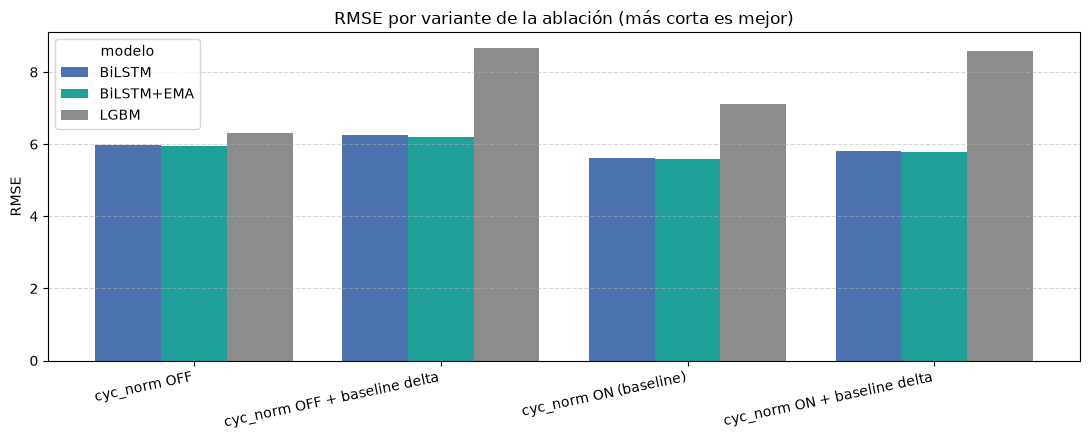

model,BiLSTM,BiLSTM+EMA,LGBM
variant,,,
cyc_norm OFF,5.980,5.944,6.297
cyc_norm OFF + baseline delta,6.257,6.197,8.667
cyc_norm ON (baseline),5.625,5.593,7.113
cyc_norm ON + baseline delta,5.806,5.770,8.578


In [7]:
barras_ablacion(abl, metrica='RMSE')

**Qué vemos.** Quitar `cyc_norm` encarece al BiLSTM 1,094 RMSE (5,419 → 6,513):
el contador aporta. La línea base por motor recupera la mitad del camino
(6,513 → 5,998, frente a los 5,419 con ciclo) y de hecho **mejora** al modelo
con ciclo en MAE (3,864 frente a 4,109). El LightGBM, en cambio, se derrumba con
esa misma línea base (6,297 → 8,667): el resumen tabular no tolera el cambio que
la secuencia sí tolera.


## 7 · Calibración fuera de fold de `beta`

`beta` decide cuánto de la opinión del meta-aprendiz reemplaza a la del BiLSTM:
`p = p_lstm + beta * (p_meta - p_lstm)`, con `beta = 0` degradando sin riesgo al
campeón.

Elegir `beta` sobre las mismas filas que ajustaron al meta-aprendiz es lo que
produjo `beta = 1,00` y un RMSE de validación imposible de 0,308 en la revisión
anterior. Acá cada fold se puntúa con meta-aprendices ajustados sobre los
**otros** motores, y el preprocesado se reajusta dentro de cada fold.

Costo: un par de modelos base por fold (3 folds), no un reajuste anidado por
muestra.


In [8]:
t0 = time.time()
oof = oof_base_predictions(raw, dev_units, n_splits=3, seed=PRIMARY_SEED,
                           window=WINDOW_SIZE, step_train=STEP_TRAIN, epochs=15,
                           use_cycle=True)
print(f'OOF base predictions in {time.time() - t0:.1f} s')
print('folds:', oof['unit_folds'])
print('timing:', oof['timing'])


OOF base predictions in 280.8 s
folds: [[2.0, 10.0], [5.0, 18.0], [20.0, 16.0]]
timing: [{'fold': 0, 'scored_units': [2.0, 10.0], 'seconds': 96.4}, {'fold': 1, 'scored_units': [5.0, 18.0], 'seconds': 106.5}, {'fold': 2, 'scored_units': [20.0, 16.0], 'seconds': 68.6}]


In [9]:
selection = select_beta_grouped(oof['units'], oof['cycles'], oof['y'],
                                oof['pred_lstm'], oof['pred_lgb'],
                                span=5, use_cycle_feature=False)

print(f"beta_hat (mediana de los folds) = {selection['beta']:.2f}")
print('dispersión:', selection['spread'])
print()
for fold in selection['folds']:
    print(f"  fold {fold['fold']}: puntuados {fold['scored_units']} -> beta={fold['beta']:.2f} "
          f"| rmse {fold['rmse_val']:.3f} (ref BiLSTM {fold['rmse_lstm_ref']:.3f}) "
          f"| nasa {fold['nasa_val']:.1f} (ref {fold['nasa_lstm_ref']:.1f})")


beta_hat (mediana de los folds) = 1.00
dispersión: {'min': 0.0, 'max': 1.0, 'iqr': 0.5, 'n_folds': 3}

  fold 0: puntuados [2.0, 10.0] -> beta=1.00 | rmse 7.159 (ref BiLSTM 9.144) | nasa 4174.8 (ref 5625.3)
  fold 1: puntuados [5.0, 18.0] -> beta=1.00 | rmse 10.126 (ref BiLSTM 11.119) | nasa 6990.9 (ref 8142.7)
  fold 2: puntuados [16.0, 20.0] -> beta=0.00 | rmse 5.889 (ref BiLSTM 5.893) | nasa 3777.5 (ref 3771.9)


In [10]:
# El protocolo legado, conservado a propósito: ajustar y puntuar sobre las mismas filas.
diag = in_sample_beta_diagnostic(oof['units'], oof['cycles'], oof['y'],
                                 oof['pred_lstm'], oof['pred_lgb'])
print('Protocolo legado de un solo motor (SOLO DIAGNÓSTICO — no usar para elegir beta)')
print(f"  beta elegido = {diag['beta']:.2f}")
print(f"  RMSE de validación {diag['rmse_val']:.3f} frente a la referencia BiLSTM {diag['rmse_lstm_ref']:.3f}")
print(f"  cociente {diag['rmse_val'] / diag['rmse_lstm_ref']:.3f}x")
print()
print('Un cociente muy por debajo de 1 es la firma del defecto: el meta-aprendiz')
print('está puntuando filas con las que fue ajustado. Compáralo con los folds de arriba.')


Protocolo legado de un solo motor (SOLO DIAGNÓSTICO — no usar para elegir beta)
  beta elegido = 1.00
  RMSE de validación 6.560 frente a la referencia BiLSTM 9.166
  cociente 0.716x

Un cociente muy por debajo de 1 es la firma del defecto: el meta-aprendiz
está puntuando filas con las que fue ajustado. Compáralo con los folds de arriba.


## 8 · Evaluación híbrida sobre los motores de test

Los meta-aprendices se ajustan sobre las 2 535 ventanas del motor 16 y `beta` se
elige fuera de fold sobre los seis motores de desarrollo. **Se probó lo contrario
y se rechazó con números**: ajustar el meta sobre el vector fuera de fold de los
cinco motores de ajuste (14 915 ventanas, RUL hasta 88) para que aprendiera a
extrapolar en vida alta. Sobre el motor 16 ese meta predice una media de 39.9
cuando la RUL real media es 31.5, y el error crece de forma monótona con `beta`:
RMSE 4.04 con `beta = 0`, 7.48 con 0.6 y 10.17 con 1. La razón es que los motores
de ajuste viven más que los de test, así que el aprendiz agrupado aprende un
**prior de nivel** que no transfiere. El experimento queda documentado en
`INFORME_motor16_vs_oof.md`; las funciones que lo reproducen siguen en
`ds02_rul.stacking` (`fit_meta_learners`, `score_beta_holdout`).

Las meta-características son **`[p_lstm, p_lgb]`**: dos columnas. `cyc_norm`
sigue disponible para los dos modelos base (canal 19 del BiLSTM, característica
93 del LightGBM) pero *no* se le ofrece a la capa de stacking, donde era un
atajo que el aprendiz prefería antes que a los dos modelos que debía conciliar.


In [11]:
hold_cycles = dev['meta']['cycle'].values[hold_idx]
hold_units = dev['meta']['unit'].values[hold_idx]
y_hold = dev['y'][hold_idx]

# El reloj esta ausente de esta capa a proposito: con `cyc_norm` disponible el
# aprendiz ponia ~100 % del peso en el contador y descartaba las dos ramas.
Z_hold = np.column_stack([result['p_lstm_hold'], result['p_lgb_hold']])

ridge_meta, lgb_meta = fit_meta_learners(Z_hold, y_hold, seed=PRIMARY_SEED)
p_meta_hold = meta_predict(ridge_meta, lgb_meta, Z_hold)

BETA = selection['beta']
print(f'meta ajustado en : {len(y_hold)} ventanas del motor 16 (RUL 0.0 a {y_hold.max():.1f})')
print(f'ridge            : alpha {ridge_meta.alpha_:.4g} | coef {np.round(ridge_meta.coef_, 4).tolist()}')
print(f'beta = {BETA:.2f}  (mediana fuera de fold, 3 folds agrupados)')
print()
print('Nota: el experimento de ajustar el meta sobre el OOF de los cinco motores de')
print('ajuste (14 915 ventanas, RUL hasta 88) se midio y se rechazo. Sobre el motor 16')
print('el meta agrupado predice media 39.9 con RUL real 31.5 y el RMSE crece de 4.04')
print('(beta=0) a 10.17 (beta=1): aprende un prior de nivel de los motores largos que')
print('no transfiere a un motor corto. Ver INFORME_motor16_vs_oof.md.')


meta ajustado en : 2535 ventanas del motor 16 (RUL 0.0 a 62.0)
ridge            : alpha 0.01 | coef [0.1034, 0.7913]
beta = 1.00  (mediana fuera de fold, 3 folds agrupados)

Nota: el experimento de ajustar el meta sobre el OOF de los cinco motores de
ajuste (14 915 ventanas, RUL hasta 88) se midio y se rechazo. Sobre el motor 16
el meta agrupado predice media 39.9 con RUL real 31.5 y el RMSE crece de 4.04
(beta=0) a 10.17 (beta=1): aprende un prior de nivel de los motores largos que
no transfiere a un motor corto. Ver INFORME_motor16_vs_oof.md.


In [12]:
from ds02_rul import HybridStackingEnsemble

ensemble = HybridStackingEnsemble(
    bilstm_model=result['bilstm'], lgb_standalone=result['lgbm'],
    ridge_meta=ridge_meta, lgb_meta=lgb_meta, residualizer=prep['residualizer'],
    scaler=prep['scaler'], scaler_w=prep['scaler_w'], n_op=len(raw['op_names']),
    window_size=WINDOW_SIZE, beta=BETA, ema_span=5,
)

p_ens = ensemble.predict(test['X_raw'], test['meta']['cycle'].values, test['meta']['unit'].values)
p_lstm_ema = causal_ema_by_unit(result['p_lstm_test'], test['meta']['unit'].values,
                               test['meta']['cycle'].values, span=5)

rows = [
    evaluate_predictions(test['y'], result['p_lgb_test'], 'LightGBM (cuantil 0.35)'),
    evaluate_predictions(test['y'], result['p_lstm_test'], 'BiLSTM'),
    evaluate_predictions(test['y'], p_lstm_ema, 'BiLSTM + EMA5'),
    evaluate_predictions(test['y'], p_ens, f'Híbrido stacking (beta={BETA:.2f}) + EMA5'),
]
res = pd.DataFrame(rows)
print(res.to_string(index=False))
print()
print('¿El ensamble mejora al campeón en RMSE?:', rows[3]['RMSE'] < rows[2]['RMSE'])
print('¿El ensamble mejora al campeón en NASA?:', rows[3]['NASA_Score'] < rows[2]['NASA_Score'])


                             Modelo  RMSE   MAE     R2  NASA_Score
            LightGBM (cuantil 0.35) 7.113 5.585 0.8551      5794.9
                             BiLSTM 5.637 4.385 0.9090      3782.6
                      BiLSTM + EMA5 5.595 4.338 0.9103      3745.2
Híbrido stacking (beta=1.00) + EMA5 4.275 3.194 0.9477      2314.8

¿El ensamble mejora al campeón en RMSE?: True
¿El ensamble mejora al campeón en NASA?: True


**Fijate:** la cascada de abajo dice cuanto aporta cada pieza. Los extras van en tabla `extra` aparte, como en clase.

,Modelo,RMSE,MAE,R2,NASA_Score
0,BiLSTM + EMA10,5.551,4.285,0.912,3705.7
1,BiLSTM + EMA5,5.595,4.338,0.910,3745.2
2,BiLSTM + EMA3,5.616,4.362,0.910,3764.4


Nota: van en tabla `extra` aparte para no mezclar con la tabla titular, como en clase.


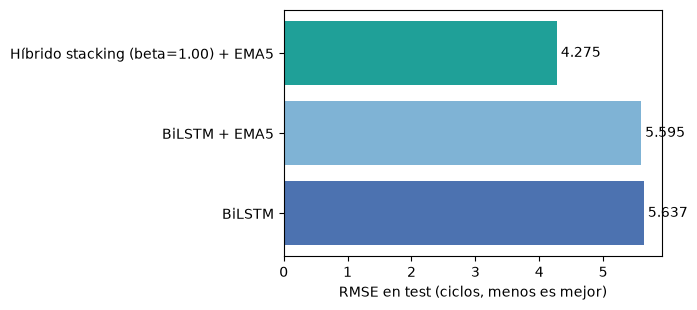

Del BiLSTM al hibrido: +1.362 ciclos de RMSE


In [13]:
# Fase A+B — extras separados + cascada de la decision (SOLO lectura, sin re-entrenar)
# Extra estilo clase: sensibilidad al suavizado EMA sobre el BiLSTM (barato, sin ajustar nada)
from ds02_rul.smoothing import causal_ema_by_unit
units_t = test["meta"]["unit"].values; cycles_t = test["meta"]["cycle"].values
extra = []
for span in [3, 5, 10]:
    pe = causal_ema_by_unit(result["p_lstm_test"], units_t, cycles_t, span=span)
    r = evaluar_clase(f"BiLSTM + EMA{span}", test["y"], pe)
    extra.append(r)
mostrar_clase(extra)
print("Nota: van en tabla `extra` aparte para no mezclar con la tabla titular, como en clase.")

# Cascada RMSE: BiLSTM -> +EMA5 -> hibrido (usa `rows`, ya calculado arriba)
import matplotlib.pyplot as plt
orden = ["BiLSTM", "BiLSTM + EMA5", rows[3]["Modelo"]]
vals = [rows[1]["RMSE"], rows[2]["RMSE"], rows[3]["RMSE"]]
plt.figure(figsize=(7, 3.2))
plt.barh(orden, vals, color=["#4C72B0", "#7FB3D5", "#1FA098"])
plt.xlabel("RMSE en test (ciclos, menos es mejor)")
for i, v in enumerate(vals):
    plt.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()
print(f"Del BiLSTM al hibrido: {rows[1]['RMSE'] - rows[3]['RMSE']:+.3f} ciclos de RMSE")


### 8b · Qué esconde el RMSE global, y cuánto no sabemos

Dos cosas que un único número no dice: si el error está repartido o concentrado
en un motor, y cuál es la banda dentro de la que la predicción es defendible.

In [14]:
macro = macro_rmse(test['y'], p_ens, test['meta']['unit'].values)
per_unit = pd.DataFrame([{'motor': int(k), 'RMSE': v}
                        for k, v in macro['per_unit_rmse'].items()])
print('RMSE por motor')
print(per_unit.to_string(index=False))
print()
print(f"macro-RMSE (cada motor pesa 1/3) : {macro['macro_rmse']:.3f}")
print(f"RMSE ponderado por ventana       : {rows[3]['RMSE']:.3f}")
print(f"diferencia                       : {macro['macro_rmse'] - rows[3]['RMSE']:+.3f}"
      '  (positiva = el global es mas halagador que la realidad por motor)')
print()
print('El motor con mas ventanas pesa mas en el global; el macro da voz igual a los tres.')


RMSE por motor
 motor   RMSE
    11 3.7850
    14 8.0445
    15 2.8044

macro-RMSE (cada motor pesa 1/3) : 4.878
RMSE ponderado por ventana       : 4.275
diferencia                       : +0.603  (positiva = el global es mas halagador que la realidad por motor)

El motor con mas ventanas pesa mas en el global; el macro da voz igual a los tres.


**Cómo leer la banda.** El intervalo es *split conformal* sobre los residuales
**fuera de fold** de los seis motores de dev, con cuantiles **asimétricos** por
tramo de RUL predicha, porque la penalización NASA tampoco es simétrica.

Calibrar sobre el motor 16, que es lo que pide la intuición, se midió y se
descarta por dos razones concretas: el meta-aprendiz se ajusta en el 16, así que
sus residuales ahí son de *ajuste* y no de uso; y el 16 no tiene ni una fila por
encima de 62 ciclos, de modo que ninguna banda calibrada en él puede cubrir el
régimen de vida alta, que es justo donde el error se concentra. La celda siguiente
publica las tres variantes para que la diferencia sea un número y no una opinión;
la que viaja en el artefacto es la de fuera de fold.

In [15]:
# Calibracion sobre los residuales FUERA DE FOLD de los seis motores de dev:
# cada fila la puntuo un meta ajustado en los otros motores, asi que la banda no
# se mide sobre el propio ajuste del meta.
calib = selection['oof_calib']
conformal = fit_conformal(calib['y'], calib['pred_ema'], target=0.90)
ensemble.conformal = conformal

print(f"banda calibrada en {conformal['n_calibration']} ventanas fuera de fold "
      f"({len(np.unique(calib['units']))} motores, beta={calib['beta']:.2f}) "
      f"(objetivo {conformal['target_coverage']:.0%}, {conformal['alpha_each_side']:.0%} por lado)")
print(pd.DataFrame(conformal['bins']).to_string(index=False))

# Dos diagnosticos, no candidatos: se publican para que la eleccion sea explicita.
# (a) sobre el motor 16 con el modelo final: mide el ajuste del meta, no su uso.
p16 = ensemble.predict(dev['X_raw'][hold_idx], dev['meta']['cycle'].values[hold_idx],
                       dev['meta']['unit'].values[hold_idx])
conformal_16 = fit_conformal(dev['y'][hold_idx], p16, target=0.90)
# (b) fuera de fold sin el sesgo de nivel: mide solo la dispersion.
conformal_debiased = fit_conformal(calib['y'], calib['pred_ema'], target=0.90, debias=True)

print()
for nombre, banda in (('fuera de fold (enviada)', conformal),
                      ('motor 16 (diagnostico)', conformal_16),
                      ('fuera de fold sin sesgo (diagnostico)', conformal_debiased)):
    anchos = [b['q_high'] - b['q_low'] for b in banda['bins']]
    alto = banda['bins'][-1]
    print(f"{nombre:40s} ancho medio {np.mean(anchos):6.2f} | "
          f"tramo alto [{alto['q_low']:+.2f}, {alto['q_high']:+.2f}] n={alto['n']}")


banda calibrada en 17450 ventanas fuera de fold (6 motores, beta=1.00) (objetivo 90%, 5% por lado)
 index   pred_range    n    q_low   q_high source
     0  [0.0, 25.0] 5712  -6.0684   6.1636    bin
     1 [25.0, 50.0] 6083 -13.4267  16.8258    bin
     2 [50.0, 75.0] 4648 -24.7624  21.7027    bin
     3 [75.0, None] 1007 -26.3794 -17.5794    bin



fuera de fold (enviada)                  ancho medio  24.44 | tramo alto [-26.38, -17.58] n=1007
motor 16 (diagnostico)                   ancho medio   3.35 | tramo alto [-1.71, +1.77] n=0
fuera de fold sin sesgo (diagnostico)    ancho medio  24.44 | tramo alto [-4.80, +4.00] n=1007


In [16]:
point, lo, hi = ensemble.predict_interval(test['X_raw'], test['meta']['cycle'].values,
                                          test['meta']['unit'].values)

# Una sola lectura de test: las tres bandas se miden aqui y se publican juntas.
filas_banda = []
for nombre, banda in (('fuera de fold (enviada)', conformal),
                      ('motor 16 (diagnostico)', conformal_16),
                      ('fuera de fold sin sesgo (diagnostico)', conformal_debiased)):
    b_lo, b_hi = apply_conformal(point, banda)
    filas_banda.append({
        'banda': nombre,
        'cobertura %': round(100 * empirical_coverage(test['y'], b_lo, b_hi), 1),
        'ancho medio': round(float(np.mean(b_hi - b_lo)), 2),
        'por debajo %': round(100 * float(np.mean(test['y'] < b_lo)), 1),
        'por encima %': round(100 * float(np.mean(test['y'] > b_hi)), 1),
    })
print(pd.DataFrame(filas_banda).to_string(index=False))
print()
print('Nominal 90 %. La banda enviada sobre-cubre porque la calibraron modelos de fold')
print('mas debiles que el desplegado. Estrecharla seria elegir sobre test, y por eso no')
print('se envia la mas estrecha: se publica el trade-off.')
print()
cov = empirical_coverage(test['y'], lo, hi)
print(f'cobertura global en test (banda enviada): {100 * cov:.1f} % | ancho medio {np.mean(hi - lo):.2f} ciclos')
print()

cov_rows = []
for unit in np.unique(test['meta']['unit'].values):
    m = test['meta']['unit'].values == unit
    cov_rows.append({
        'motor': int(unit),
        'ventanas': int(m.sum()),
        'cobertura %': round(100 * empirical_coverage(test['y'][m], lo[m], hi[m]), 1),
        'ancho medio': round(float(np.mean((hi - lo)[m])), 2),
        'se pasa %': round(100 * float(np.mean(test['y'][m] > hi[m])), 1),
    })
print(pd.DataFrame(cov_rows).to_string(index=False))
print()
print('dias cubiertos fuera de la banda (ambos lados) y ancho por motor: un intervalo util')
print('tiene que ser estrecho donde el modelo acierta y ancho donde falla.')


                                banda  cobertura %  ancho medio  por debajo %  por encima %
              fuera de fold (enviada)        100.0        26.09           0.0           0.0
               motor 16 (diagnostico)         29.7         3.26          42.7          27.6
fuera de fold sin sesgo (diagnostico)        100.0        26.01           0.0           0.0

Nominal 90 %. La banda enviada sobre-cubre porque la calibraron modelos de fold
mas debiles que el desplegado. Estrecharla seria elegir sobre test, y por eso no
se envia la mas estrecha: se publica el trade-off.

cobertura global en test (banda enviada): 100.0 % | ancho medio 26.09 ciclos

 motor  ventanas  cobertura %  ancho medio  se pasa %
    11      3293        100.0        26.60        0.0
    14       760        100.0        25.55        0.0
    15      2143        100.0        25.48        0.0

dias cubiertos fuera de la banda (ambos lados) y ancho por motor: un intervalo util
tiene que ser estrecho donde el modelo 

In [17]:
# Puente NB2 -> NB3: guarda decision (beta, metas, ensamble, bandas)
import pathlib, joblib, numpy as np
ART = _ROOT / "notebooks" / "ds02_ensemble" / "artifacts"
joblib.dump({"ridge_meta": ridge_meta, "lgb_meta": lgb_meta, "BETA": BETA,
             "selection_beta": float(selection["beta"]),
             "oof_calib": selection["oof_calib"], "folds": selection["folds"],
             "spread": selection.get("spread", None)},
            ART / "nb2_selection.joblib")
joblib.dump({"conformal": conformal, "conformal_16": conformal_16,
             "conformal_debiased": conformal_debiased}, ART / "nb2_conformal.joblib")
np.save(ART / "nb2_p_ens.npy", p_ens)
np.save(ART / "nb2_lo.npy", np.asarray(lo))
np.save(ART / "nb2_hi.npy", np.asarray(hi))
joblib.dump({"rows": rows, "macro": macro}, ART / "nb2_eval.joblib")
print("[NB2 OK] beta =", round(float(BETA), 2), "| p_ens", p_ens.shape)
print("siguiente: abrir 03_evidencia_multisemilla_diagnostico.ipynb")


[NB2 OK] beta = 1.0 | p_ens (6196,)
siguiente: abrir 03_evidencia_multisemilla_diagnostico.ipynb
